# Phase 9: Biological interpretation

We asked what biology the translations between single-cell pseudobulk and whole-blood bulk profiles carry: which gene programs they track, whether what they track is a stable trait of the person or specific to one blood draw, whether they follow a visit-level event with a known cause (the plasmablast response seven days after flu vaccination), whether they keep traits of the person (sex, cytomegalovirus (CMV) status, human leukocyte antigen (HLA) genotype), and what adversarial training changes beyond the simple alignment each generator starts from. The analysis was decided after the single test evaluation, so it is post-hoc and exploratory; it uses only the 135 validation pairs from 14 donors, which also chose the CycleGANs' settings and checkpoints, and training targets for descriptive references. Most immune programs, from the lineage markers to interferon and the CMV-associated cytotoxic program, are already tracked by the starting alignment (9 of 13 programs in single-cell → bulk, 10 of 12 in bulk → single-cell), and what they track is mostly the person rather than the visit; the unpaired CycleGAN mostly inherits that tracking (6 of 13 and 8 of 12), is below its start for the interferon, platelet and monocyte programs in single-cell → bulk (and above it, though neither is tracked, for the erythroid and ribosomal programs), and is above it for the plasmablast and T-marker programs in bulk → single-cell. Signal that the single-cell input lacks is barely inferred: only paired ridge regression tracks the whole-blood granulocyte program, nothing tracks the erythroid program, and for the Day 7 plasmablast rise, which is present in the true validation profiles, only paired ridge regression meets the tracking rule (bulk → single-cell) among the start, the locked CycleGANs and paired ridge regression; the averaged-weight unpaired CycleGAN also meets it there, by 0.01 (lower bound 0.441 against 0.431), on the donors that chose it. Beyond its start, the unpaired CycleGAN's changes carry little information about the specific sample (median partial correlation with the true partner 0.047, 95% CI 0.014 to 0.089, in single-cell → bulk and 0.077, 0.049 to 0.112, in bulk → single-cell; §4.5), no more than the unpaired CORAL alignment, while paired ridge regression's carry more.

## 1. Aim

The earlier phases measured how much the translations recover in aggregate: accuracy, realism and cell-type composition. This phase asks what that recovery consists of, in terms a biologist would use: named gene programs, the split between a person's stable traits and visit-to-visit change, a known visit-level response, and traits of the person. It also asks which of these the CycleGANs add beyond the alignment they start from, and which only paired supervision adds.

## 2. Data

- **Validation split** (135 pairs, 14 donors, 8–10 blood draws each): every translation is scored here.
- **Training split** (582 pairs, 68 donors): used for the z-score parameters of each program, each program's between-donor variance share, the composition coefficients of the partial correlation, and the vaccine-response gate. The no-information reference draws from the target profiles of the training halves, the two donor-disjoint halves of the training donors on which the unpaired models were trained (Phase 1).
- **Sample metadata** (visit timepoint, sex, CMV status), joined for training and validation samples only.
- **Gene sets:** the short list of programs fixed before the run (§3) and the Hallmark sets of the Molecular Signatures Database (MSigDB, release 2024.1; Liberzon et al., 2015), restricted to the 5,000-gene panel; 49 of the 50 sets have at least 10 panel genes and are reported.
- **Test split:** never read; its expression and composition are masked before any analysis.

## 3. Methods

**Translators.** A translator with several members (seeds or training steps) is scored member by member, and the scores are averaged.
- *Starting alignment:* the affine map each generator starts from, mean shift in single-cell → bulk and ComBat (Johnson et al., 2007) in bulk → single-cell, fit on the training halves.
- *Unpaired CycleGAN* (Zhu et al., 2017), trained on the training halves without pairs, and *CycleGAN + composition labels*, the same model with a composition task loss whose labels come from composition networks trained on all training pairs (Phase 3). Both enter in two readouts: *locked*, the three seeds at the checkpoints chosen in Phase 3, and *averaged weights*, an exponential moving average of the generator weights taken at three late training steps of three further seeds (Phase 5).
- *CycleGAN + cross-fitted labels:* CycleGAN + composition labels with composition networks cross-fitted over the 68 training donors, so that each label comes from a network that never saw that sample's donor (Phase 5); averaged weights only.
- *Paired ridge regression:* the ridge + spread baseline of Phase 1, fit on all 582 training pairs; the paired reference.

Each translator is regenerated from its saved model and checked against the accuracy and composition values reported in its own phase.

**References.** The *no-information reference* replaces each translation with a random real training-half profile of the target assay; drawn 200 times, it gives the null band (2.5th–97.5th percentile) of every correlation. The *same-donor reference*, a real profile from another draw of the same donor, is mechanical: its between-donor correlation is near 1 by construction, so it serves only as a check against Phase 6.

**Programs.** A program's score for a sample is the mean of its genes' expression, each gene z-scored with the training targets' mean and standard deviation (SD); the granulocyte score is the plain mean of its 7 genes (as in Phase 6) and is used for single-cell → bulk only. The short list: granulocyte, erythroid, platelet, interferon response, plasmablast and immunoglobulin, CMV-associated cytotoxic, identity (XIST and four HLA genes), the T-cell, B-cell, natural killer (NK), monocyte and dendritic-cell (DC) marker programs, and the 34 ribosomal genes as an assay-artifact control.

**Measures.**
- *Tracking:* the Pearson correlation r across validation samples between the translated and the true program score, reported with the slope (r ignores scale) and as Δr, the difference from the starting alignment's r, with paired donor-bootstrap 95% confidence intervals (CIs; 1,000 resamples of the 14 donors).
- *Person versus visit:* each program's between-donor variance share (one-way intraclass correlation) on the training targets; a share of 0.5 or more labels it person-level. On validation, tracking is split into a between-donor r (across the 14 donor means) and a within-donor r (after removing each donor's mean). The share each translator recovers is r² within each component; it is not estimable when the component holds under 10% of the true score's variance.
- *Composition-adjusted (partial) r,* in bulk → single-cell: both scores minus a linear fit on the true peripheral blood mononuclear cell (PBMC) composition, with coefficients fit on training targets.
- *Decision rules, fixed before the run:* a program is *tracked* when the CI lower bound of its r exceeds the upper end of the null band; *inherited from the alignment* when a CycleGAN's Δr CI includes 0 and the start is tracked (otherwise *no different from the start*); and *above* or *below the start* when the Δr CI excludes 0. "Inherited" does not require the CycleGAN itself to pass the tracking rule. Paired ridge regression, which does not start from the alignment, reads *no different from the start* whenever its Δr CI includes 0, even when the start is tracked.

**The vaccine response.** The unit is the donor-year with Day 0 and Day 7 draws of a flu-vaccine year (116 in training, 26 in validation from 14 donors); intervals resample donors, keeping a donor's years together. A gate requires the Day 7 − Day 0 plasmablast change in the training targets of the direction's target assay to have a CI above 0. The interferon response, which peaks around Day 1 after inactivated vaccine, is a secondary readout with an expected null. On validation, the true change is *present* when its CI excludes 0; when it is not present, the translators *cannot be judged*.

**Traits of the person.** Sex: the female − male difference in XIST, in training-target SD units, translated against true (9 female and 5 male validation donors). CMV: the CMV-positive − CMV-negative difference in the CMV-associated program (8 positive, 6 negative donors). HLA: the between-donor r of the HLA genes. Bootstraps are stratified by the trait.

**What adversarial training changes.** Per gene and across validation samples, the partial correlation of the translator's move away from its start with the true partner, controlling for the start: both are regressed on the start and the residuals correlated. A move that is an affine function of the start is null by construction. The unpaired CORAL alignment (Sun et al., 2016), fit on the training halves, is an unpaired linear reference: it uses no pairs but, unlike the start, mixes genes, so its move can carry sample-specific information.

## 4. Results

### 4.1 Setup, guards and translators

The first code cell records the setup stamp, masks the test split and joins the metadata; the second regenerates every translator and checks it against the values reported in its own phase.

In [1]:
import os, sys, json, warnings, hashlib, pickle
from pathlib import Path
os.environ["PYTHONWARNINGS"] = "ignore:An input array is constant"
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dgm").is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import torch
import anndata as ad
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import Markdown, display
from scipy.linalg import LinAlgWarning

from dgm import paths, analysis as an, biology as bi, composition as comp, translation as tr
from dgm.baselines import RidgeSpread
from dgm.metrics import GRANULOCYTE
from dgm.models import canonical_hash
from dgm.notebook import setup
from dgm.plotting import DOMAIN, INK, INK_2, MUTED, SERIES, THRESHOLD, figure, label, panel_labels, save_show

warnings.filterwarnings("ignore", category=LinAlgWarning)
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message=".*CUDA.*")
info = setup(seed=0, notebook="phase9_biology.ipynb")
comp.deterministic()
R = {k: paths.results_dir(k) for k in range(10)}
RESULTS, FIG = paths.results_dir(9), paths.results_dir(9, "figures")
TOUCH = R[7] / "test_touch.json"
assert len(json.loads(TOUCH.read_text())) == 2

ctx0 = tr.SoundLife(0)
P = ctx0.pairs
bi.mask_test(P)                                                 # every Phase 9 code path reads this one pairs object
assert ctx0.pairs is P and np.isnan(P.x_bulk[P.split == "test"]).all()
rows = bi.row_guard(P)
va, tr_idx = rows("val"), rows("train")
assert (va == ctx0.va).all()
DIRS = tr.DIRECTIONS
donors_va, Cv = P.donor_ids[va], P.composition[va]
n_va, NG = len(va), P.x_sc.shape[1]
GENES = list(P.genes)
TGT_ALL = {"S->B": P.x_bulk, "B->S": P.x_sc}                    # target assay of each direction
mu_t = {d: bi.zparams(TGT_ALL[d][tr_idx]) for d in DIRS}         # z-score parameters: training targets only

# Metadata: joined on training and validation sample ids only
obs = ad.read_h5ad(paths.PROCESSED / "bulk_counts.h5ad", backed="r").obs
keep = np.concatenate([tr_idx, va])
META = obs.loc[P.sample_ids[keep], ["donor_id", "timepoint", "sex", "cmv"]].copy()
assert (META["donor_id"].to_numpy() == P.donor_ids[keep]).all() and not np.isin(P.sample_ids[P.split == "test"], META.index).any()
META.index = keep
tp = {s: META.loc[rows(s), "timepoint"].astype(str).to_numpy() for s in ("train", "val")}

def show_caption(name):
    f = FIG / "captions.md"
    text = f.read_text() if f.exists() else ""
    if f"\n## {name}\n" in text:
        display(Markdown(text.split(f"\n## {name}\n", 1)[1].split("\n## ", 1)[0].strip()))
SHOWN_NAME = {"start": "starting alignment"}                    # display names only; the CSVs keep their values
def show_table(title, df, columns=None):
    """A results table under its bold title, with display column names (the CSVs are unchanged)."""
    display(Markdown(title))
    out = df.rename(columns=columns or {})
    if "translator" in out.columns:
        out = out.assign(translator=out["translator"].replace(SHOWN_NAME))
    with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", None):
        display(out.round(3))
print(f"validation {n_va} pairs, {len(np.unique(donors_va))} donors; training {len(tr_idx)}; test rows masked")

commit: 5b2325d | notebook_source: a4716bf51bd1 (= HEAD) | python: 3.10.14 | numpy: 1.26.4 | seed: 0 | torch: 2.8.0+cu129 | cuda: False


validation 135 pairs, 14 donors; training 582; test rows masked


In [2]:
# Translators: every member's validation translations, regenerated from saved models and checked.
KEEP = (15000, 17500, 20000)
M1c = tr.config(lambda_cyc=20.0, identity=True); M2c = tr.config(lambda_cyc=20.0, identity=True, lambda_task=10.0)
DEF5 = dict(ema=0.999, keep_states=KEEP); KEY5 = "41dab869bea05335"
def cached_run(phase, key, cfg, seed):
    c = tr.config(**cfg)
    name = hashlib.sha256(json.dumps([key, c, seed, 0], sort_keys=True, default=str).encode()).hexdigest()[:16]
    return pickle.loads((paths.PROCESSED / f"phase{phase}" / f"run_{name}.pkl").read_bytes())
P3REG = json.loads((R[3] / "models.json").read_text())
locked = {m: [torch.load(paths.REPO / "data" / "models" / "phase3" / f"{m}_seed{s}.pt", weights_only=False)["state"] for s in (0, 1, 2)]
          for m in ("M1", "M2")}
for m in locked:
    for s, st in enumerate(locked[m]):
        assert canonical_hash(st) == P3REG[f"{m}_seed{s}"]["canonical_hash"]
ema = {"M1 (EMA)": [cached_run(5, KEY5, dict(M1c, **DEF5), s) for s in (6, 7, 8)],
       "M2 (EMA)": [cached_run(5, KEY5, dict(M2c, **DEF5), s) for s in (6, 7, 8)],
       "B-cf (EMA)": [cached_run(5, KEY5, dict(M2c, task_nets="crossfit", **DEF5), s) for s in (6, 7, 8)]}
def apply(state, d, x):
    g = tr.load_generators(state, NG, 512)[0 if d == "S->B" else 1]
    with torch.no_grad():
        return g(torch.as_tensor(np.asarray(x, np.float32))).numpy().astype(float)
def start_of(d, x):
    a0, b0 = ctx0.init[d]
    return np.maximum(np.asarray(x, float) * a0 + b0, 0)
SRC_ALL = {"S->B": P.x_sc, "B->S": P.x_bulk}
def r2_med(y, d):
    mu, t = ctx0.ev[d].mean_, ctx0.tgt[d]
    return float(np.median(1 - ((y - t) ** 2).sum(1) / ((t - mu) ** 2).sum(1)))
marker_r2 = lambda y, d: comp.comp_r2(ctx0.marker[d].predict(y), Cv)

rs_fit = {d: RidgeSpread().fit(SRC_ALL[d][tr_idx], TGT_ALL[d][tr_idx], P.donor_ids[tr_idx], comp=P.composition[tr_idx],
                               age=P.age_group[tr_idx], genes=ctx0.genes, direction=d) for d in DIRS}
NAMES = {"start": "start", "M1": "unpaired CycleGAN", "M2": "CycleGAN + composition labels", "M1 (EMA)": "unpaired CycleGAN (averaged)",
         "M2 (EMA)": "CycleGAN + composition labels (averaged)", "B-cf (EMA)": "CycleGAN + cross-fitted labels (averaged)",
         "ridge + spread": "paired ridge regression"}
def translator(name, d, x):
    """Every member's translation of sources x (rows are samples)."""
    if name == "start":
        return [start_of(d, x)]
    if name in ("M1", "M2"):
        return [apply(st, d, x) for st in locked[name]]
    if name in ema:
        return [apply(r["kept_ema"][k], d, x) for r in ema[name] for k in KEEP]
    return [np.asarray(rs_fit[d].translate(np.asarray(x, float)), float)]
OUT = {(n, d): translator(n, d, ctx0.src[d]) for n in NAMES for d in DIRS}

p3 = pd.read_csv(R[3] / "models_vs_baselines_val.csv"); p1 = pd.read_csv(R[1] / "baselines_val.csv")
runs5 = pd.read_csv(R[5] / "runs_val.csv"); pbr = pd.read_csv(R[6] / "pairs_buy_references_val.csv")
for d in DIRS:
    start_name = {"S->B": "mean shift", "B->S": "ComBat"}[d]
    row = p3[(p3.direction == label(d)) & (p3.method == f"{start_name} (training halves)")].iloc[0]
    assert abs(r2_med(OUT[("start", d)][0], d) - row["r2_centered"]) < 1e-6 and abs(marker_r2(OUT[("start", d)][0], d) - row["marker composition R²"]) < 1e-6
    for m in ("M1", "M2"):
        row = p3[(p3.direction == label(d)) & (p3.method == f"{m} (mean of 3 seeds)")].iloc[0]
        assert abs(np.mean([r2_med(y, d) for y in OUT[(m, d)]]) - row["r2_centered"]) < 1e-6
        assert abs(np.mean([marker_r2(y, d) for y in OUT[(m, d)]]) - row["marker composition R²"]) < 1e-6
    for name, runs in ema.items():                              # each kept averaged state reproduces its logged evaluation
        ys = OUT[(name, d)]
        want = [next(e for e in r["evals"] if e["step"] == k)["ema"] for r in runs for k in KEEP]
        assert np.allclose([r2_med(y, d) for y in ys], [w[f"{d} r2_centered"] for w in want], atol=1e-6)
        assert np.allclose([marker_r2(y, d) for y in ys], [w[f"{d} marker comp_r2"] for w in want], atol=1e-6)
        cond = {"M1 (EMA)": "M1", "M2 (EMA)": "M2", "B-cf (EMA)": "B-cf cross-fitted labels"}[name]
        for r in runs:                                          # and each run is the one Phase 5 reported
            lq = np.mean([e["ema"][f"{d} r2_centered"] for e in r["evals"] if e["step"] >= 15000])
            assert abs(lq - runs5[(runs5.condition == cond) & (runs5.seed == r["seed"])][f"{d} r2_centered"].iloc[0]) < 1e-9
    m1 = pbr[(pbr.direction == label(d)) & (pbr.reference == "M1 (EMA)")].iloc[0]   # Phase 6's averaged-weight M1
    assert abs(np.mean([r2_med(y, d) for y in OUT[("M1 (EMA)", d)]]) - m1["centered R²"]) < 1e-6
    assert abs(np.mean([marker_r2(y, d) for y in OUT[("M1 (EMA)", d)]]) - m1["marker composition R²"]) < 1e-6
    lin6c = pd.read_csv(R[6] / "lineage_composition_val.csv")
    want_c = lin6c[(lin6c.direction == label(d)) & (lin6c.translations == "ridge + spread (all training pairs)")]["mean over classes"].iloc[0]
    assert abs(marker_r2(OUT[("ridge + spread", d)][0], d) - want_c) < 1e-6
    rs_row = p1[(p1.direction == d) & (p1.baseline == "ridge + spread")].iloc[0]
    assert abs(r2_med(OUT[("ridge + spread", d)][0], d) - rs_row["r2_centered"]) < 1e-6, (d, r2_med(OUT[("ridge + spread", d)][0], d))

# References: the no-information reference (Phase 7's random real profile, on validation) and the same-donor draw
HT = {"S->B": ctx0.xb, "B->S": ctx0.xs}                          # training-half targets
assert np.array_equal(HT["S->B"], P.x_bulk[ctx0.half_b]) and np.array_equal(HT["B->S"], P.x_sc[ctx0.half_a])
def noinfo(d, s):
    return np.asarray(HT[d], float)[np.random.default_rng([s, 7]).integers(len(HT[d]), size=n_va)]
NULL_SEEDS = range(200)
od = an.other_draw(donors_va, seed=0)
sdr = pd.read_csv(R[6] / "same_donor_reference_val.csv")
for d in DIRS:
    assert abs(r2_med(ctx0.tgt[d][od], d) - sdr[sdr.direction == label(d)]["centered R²"].iloc[0]) < 1e-6
print("translators and references regenerated and checked:", {n: len(OUT[(n, "S->B")]) for n in NAMES})

translators and references regenerated and checked: {'start': 1, 'M1': 3, 'M2': 3, 'M1 (EMA)': 9, 'M2 (EMA)': 9, 'B-cf (EMA)': 9, 'ridge + spread': 1}


### 4.2 Programs: person versus visit

**Most programs are person-level, and what the translations track is mostly the person.** On the training targets, the CMV-associated cytotoxic, identity, NK-marker and B-marker programs, and the platelet program in bulk, are the most person-level (between-donor share 0.68–0.82), while the plasmablast and immunoglobulin program (0.26 in bulk, 0.17 in single-cell profiles) and the ribosomal genes (0.41, 0.22) vary mostly between visits (Table 9.1). Visit-level signal also crosses the assays: the starting alignment's within-donor r for the interferon program is 0.817 in single-cell → bulk, because both assays measure the same draw (Table 9.2, Figure 9.1).

The starting alignment already tracks most short-list programs, and the unpaired CycleGAN mostly inherits that tracking (Table 9.2, Figure 9.2). In single-cell → bulk it is below its start for the interferon (Δr −0.131, 95% CI −0.293 to −0.066), platelet (−0.146, −0.281 to −0.021) and monocyte-marker programs (−0.065, −0.137 to −0.009); in bulk → single-cell it is above its start for the plasmablast (0.066, 0.014 to 0.132) and T-marker programs (0.057, 0.014 to 0.108). In single-cell → bulk it is also above its start, though neither is tracked, for the erythroid (0.100, 0.001 to 0.215) and ribosomal programs (0.164, 0.018 to 0.299). The T-marker result does not conflict with Phase 6, where T-cell composition R² in bulk → single-cell falls from 0.24 to −0.23: r ignores level and scale, so the CycleGAN can rank samples' T-marker scores better than ComBat while miscalibrating their level. These are validation values on the donors that chose the CycleGANs, so they favor the CycleGANs. Paired ridge regression is above the start for 3 programs in single-cell → bulk and 5 in bulk → single-cell; it is also below the start for interferon in single-cell → bulk (−0.099, −0.188 to −0.039), where the start's r is already 0.943.

Signal that the single-cell input lacks is barely inferred (Figure 9.3). For the granulocyte program only paired ridge regression is tracked (r 0.507, 95% CI 0.258 to 0.671; null 0.150), while the start (0.388, 0.109 to 0.562) and the unpaired CycleGAN (0.337, 0.030 to 0.498) are not; ridge's gain over the start is not resolved (Δr 0.119, 95% CI −0.039 to 0.253); no translator tracks the erythroid program in either direction. Per-gene correlations by gene class are in Table 9.3; the Hallmark-set correlations form a supplementary table (§7).

In [3]:
# Short-list programs (fixed before the run) and the Hallmark sets
gi = {g: i for i, g in enumerate(GENES)}
def cols(genes):
    assert all(g in gi for g in genes), [g for g in genes if g not in gi]
    return np.array([gi[g] for g in genes])
SHORT = {"granulocyte": [g for g in GRANULOCYTE], **bi.PROGRAMS,
         **{f"{label(k)} markers": v for k, v in comp.MARKERS.items() if k != "Other"},
         "ribosomal": sorted(g for g in GENES if g.startswith(("RPL", "RPS")))}
assert len(SHORT["ribosomal"]) == 34
HALL, hall_cov = bi.read_gmt(paths.REPO / "data" / "raw" / "msigdb" / "h.all.v2024.1.Hs.symbols.gmt", GENES)
hall_cov.to_csv(RESULTS / "hallmark_coverage.csv", index=False)
print(f"{len(HALL)} of {len(hall_cov)} Hallmark sets have at least 10 panel genes")

def score(Y, prog, d):
    if prog == "granulocyte":                                   # Phase 6's definition: the plain mean of the 7 genes
        return np.asarray(Y, float)[:, cols(GRANULOCYTE)].mean(1)
    genes = SHORT.get(prog) or HALL[prog]
    return bi.program_score(Y, cols(genes), *mu_t[d])
PROGS = {d: [p for p in SHORT if not (p == "granulocyte" and d == "B->S")] for d in DIRS}

# Granulocyte check against Phase 6 (single-cell -> bulk)
lin6 = pd.read_csv(R[6] / "lineage_composition_val.csv")
t_gran = score(ctx0.tgt["S->B"], "granulocyte", "S->B")
want = lin6[(lin6.direction == label("S->B")) & (lin6.translations == "ridge + spread (all training pairs)")]["granulocyte score r"].iloc[0]
assert abs(bi.pearson(t_gran, score(OUT[("ridge + spread", "S->B")][0], "granulocyte", "S->B")) - want) < 1e-6

# Between-donor variance share of each program's true score on all training rows (orders programs; >= 0.5 person-level)
share_rows = []
for d in DIRS:
    for p in PROGS[d]:
        x = score(TGT_ALL[d][tr_idx], p, d)
        share_rows.append({"direction": label(d), "program": p, "genes": len(cols(SHORT[p])) if p in SHORT else np.nan,
                           "between-donor share (training)": bi.between_share(x, P.donor_ids[tr_idx]),
                           **{f"validation {k} share of variance (raw)": v for k, v in bi.component_share(score(ctx0.tgt[d], p, d), donors_va).items()}})
share_tab = pd.DataFrame(share_rows)
share_tab["level"] = np.where(share_tab["between-donor share (training)"] >= 0.5, "person", "visit")
share_tab.to_csv(RESULTS / "program_between_share.csv", index=False)
show_table("**Table 9.1.** Between-donor variance share of each short-list program's true score (one-way intraclass correlation) "
           "on the 582 training targets (68 donors), which sets the level (person-level at 0.5 or more), and the between- and "
           "within-donor shares of its variance on the 135 validation pairs (14 donors), which set the not-estimable rule (under 10%).",
           share_tab, {"genes": "panel genes", "validation between share of variance (raw)": "between-donor share (validation)",
                       "validation within share of variance (raw)": "within-donor share (validation)"})

49 of 50 Hallmark sets have at least 10 panel genes


**Table 9.1.** Between-donor variance share of each short-list program's true score (one-way intraclass correlation) on the 582 training targets (68 donors), which sets the level (person-level at 0.5 or more), and the between- and within-donor shares of its variance on the 135 validation pairs (14 donors), which set the not-estimable rule (under 10%).

,direction,program,panel genes,between-donor share (training),between-donor share (validation),within-donor share (validation),level
0,single-cell → bulk,granulocyte,7,0.585,0.514,0.486,person
1,single-cell → bulk,erythroid,8,0.567,0.519,0.481,person
2,single-cell → bulk,platelet,2,0.755,0.808,0.192,person
3,single-cell → bulk,interferon response,13,0.569,0.803,0.197,person
4,single-cell → bulk,plasmablast and immunoglobulin,14,0.258,0.536,0.464,visit
5,single-cell → bulk,CMV-associated cytotoxic,7,0.800,0.811,0.189,person
6,single-cell → bulk,"identity (XIST, HLA)",5,0.820,0.742,0.258,person
7,single-cell → bulk,T markers,5,0.574,0.614,0.386,person
8,single-cell → bulk,B markers,5,0.761,0.619,0.381,person
9,single-cell → bulk,Mono markers,5,0.657,0.631,0.369,person


In [4]:
# Tracking per translator: member scores -> r, between r, within r, slope (member averaged), with CIs and the null band
BOOTL = bi.donor_boot_labeled(donors_va, 1000, seed=0)
BOOT_CODES = [(idx, bi.codes_of(lab)) for idx, lab in BOOTL]
CODES = bi.codes_of(donors_va)
comp_coefs = {}                                                  # partial r (bulk -> single-cell): training composition fit
for p in PROGS["B->S"]:
    comp_coefs[p] = bi.partial_coefs(score(P.x_sc[tr_idx], p, "B->S"), P.composition[tr_idx])

def member_scores(name, d, p):
    return [score(y, p, d) for y in OUT[(name, d)]]
def tr3(true, preds, codes):
    return np.nanmean([bi.tracking_codes(true, s, codes) for s in preds], 0)
def partial3(true, preds, p, idx=None):
    idx = np.arange(n_va) if idx is None else idx
    rt = bi.residualize(true[idx], Cv[idx], comp_coefs[p])
    return np.nanmean([bi.pearson(rt, bi.residualize(s[idx], Cv[idx], comp_coefs[p])) for s in preds])

track_rows, NULL = [], {}
for d in DIRS:
    for p in PROGS[d]:
        true = score(ctx0.tgt[d], p, d)
        null = np.array([bi.tracking_codes(true, score(noinfo(d, s), p, d), CODES) for s in NULL_SEEDS])
        NULL[(d, p)] = np.nanpercentile(null, [2.5, 97.5], axis=0)          # columns r, between, within
        start_sc = member_scores("start", d, p)
        for name in NAMES:
            sc = member_scores(name, d, p)
            est = tr3(true, sc, CODES)
            boots = np.array([tr3(true[i], [s[i] for s in sc], c) for i, c in BOOT_CODES])
            dstart = np.array([tr3(true[i], [s[i] for s in sc], c)[0] - tr3(true[i], [s[i] for s in start_sc], c)[0] for i, c in BOOT_CODES])
            lo, hi = np.nanpercentile(boots, [2.5, 97.5], axis=0)
            row = {"direction": label(d), "program": p, "translator": NAMES[name],
                   "r": est[0], "r CI": f"{lo[0]:.3f} to {hi[0]:.3f}", "r lo": lo[0],
                   "between r": est[1], "between r CI": f"{lo[1]:.3f} to {hi[1]:.3f}",
                   "between r Fisher CI": "{:.3f} to {:.3f}".format(*bi.fisher_ci(est[1], len(np.unique(donors_va)))),
                   "within r": est[2], "within r CI": f"{lo[2]:.3f} to {hi[2]:.3f}",
                   "slope": np.nanmean([bi.slope(true, s) for s in sc]),
                   "Δr vs start": est[0] - tr3(true, start_sc, CODES)[0],
                   "Δr vs start CI": "{:.3f} to {:.3f}".format(*np.nanpercentile(dstart, [2.5, 97.5])),
                   "Δr lo": np.nanpercentile(dstart, 2.5), "Δr hi": np.nanpercentile(dstart, 97.5),
                   "null r hi": NULL[(d, p)][1, 0], "null between hi": NULL[(d, p)][1, 1], "null within hi": NULL[(d, p)][1, 2]}
            if d == "B->S":
                pe = partial3(true, sc, p)
                pb = np.array([partial3(true, sc, p, i) for i, _ in BOOT_CODES])
                row.update({"partial r": pe, "partial r CI": "{:.3f} to {:.3f}".format(*np.nanpercentile(pb, [2.5, 97.5]))})
            track_rows.append(row)
track = pd.DataFrame(track_rows)
track["tracked"] = track["r lo"] > track["null r hi"]
track.to_csv(RESULTS / "program_tracking_val.csv", index=False)
print(len(track), "rows")

175 rows


In [5]:
# Readings by the fixed decision rules; the recovered share per component (r² within it; not estimable < 10%)
sh = share_tab.set_index(["direction", "program"])
def reading(r):
    st = track[(track.direction == r["direction"]) & (track.program == r["program"]) & (track.translator == "start")].iloc[0]
    if r["translator"] == "start":
        return "tracked" if r["tracked"] else "not tracked"
    if r["Δr lo"] <= 0 <= r["Δr hi"]:                         # only a CycleGAN, which starts from the alignment, can inherit it
        inherits = r["translator"] != "paired ridge regression" and st["tracked"]
        return "inherited from the alignment" if inherits else "no different from the start"
    return ("above the start" if r["Δr lo"] > 0 else "below the start") + ("; tracked" if r["tracked"] else "; not tracked")
track["reading"] = track.apply(reading, axis=1)
for comp_ in ("between", "within"):
    vs = track.apply(lambda r: sh.loc[(r["direction"], r["program"]), f"validation {comp_} share of variance (raw)"], axis=1)
    track[f"recovered {comp_} share"] = np.where(vs >= 0.10, track[f"{comp_} r"].clip(lower=0) ** 2, np.nan)
track.to_csv(RESULTS / "program_tracking_val.csv", index=False)
show_table("**Table 9.2.** Tracking of each short-list program on the 135 validation pairs (14 donors): Pearson r between translated "
           "and true program scores with its donor-bootstrap 95% CI, the between-donor r (across donor means) and within-donor r "
           "(after removing donor means), Δr against the starting alignment with its paired 95% CI, and the reading under the "
           "fixed decision rules (§3), with the tracked flag and the slope of true on translated score. Bootstrap: 1,000 resamples of the 14 donors.",
           track[["direction", "program", "translator", "r", "r CI", "slope", "between r", "within r", "Δr vs start", "Δr vs start CI", "tracked", "reading"]],
           {"r CI": "r 95% CI", "between r": "between-donor r", "within r": "within-donor r", "Δr vs start": "Δr vs. start",
            "Δr vs start CI": "Δr 95% CI"})

**Table 9.2.** Tracking of each short-list program on the 135 validation pairs (14 donors): Pearson r between translated and true program scores with its donor-bootstrap 95% CI, the between-donor r (across donor means) and within-donor r (after removing donor means), Δr against the starting alignment with its paired 95% CI, and the reading under the fixed decision rules (§3), with the tracked flag and the slope of true on translated score. Bootstrap: 1,000 resamples of the 14 donors.

,direction,program,translator,r,r 95% CI,slope,between-donor r,within-donor r,Δr vs. start,Δr 95% CI,tracked,reading
0,single-cell → bulk,granulocyte,starting alignment,0.388,0.109 to 0.562,2.357,0.447,0.306,0.000,0.000 to 0.000,False,not tracked
1,single-cell → bulk,granulocyte,unpaired CycleGAN,0.337,0.030 to 0.498,0.372,0.435,0.229,-0.050,-0.221 to 0.108,False,no different from the start
2,single-cell → bulk,granulocyte,CycleGAN + composition labels,0.321,-0.012 to 0.533,0.333,0.452,0.191,-0.067,-0.334 to 0.181,False,no different from the start
3,single-cell → bulk,granulocyte,unpaired CycleGAN (averaged),0.363,0.071 to 0.516,0.397,0.441,0.271,-0.025,-0.158 to 0.112,False,no different from the start
4,single-cell → bulk,granulocyte,CycleGAN + composition labels (averaged),0.336,0.034 to 0.532,0.399,0.492,0.195,-0.052,-0.273 to 0.151,False,no different from the start
5,single-cell → bulk,granulocyte,CycleGAN + cross-fitted labels (averaged),0.367,0.088 to 0.528,0.404,0.488,0.247,-0.021,-0.184 to 0.134,False,no different from the start
6,single-cell → bulk,granulocyte,paired ridge regression,0.507,0.258 to 0.671,0.754,0.551,0.445,0.119,-0.039 to 0.253,True,no different from the start
7,single-cell → bulk,erythroid,starting alignment,-0.037,-0.244 to 0.193,-0.012,-0.008,-0.082,0.000,0.000 to 0.000,False,not tracked
8,single-cell → bulk,erythroid,unpaired CycleGAN,0.063,-0.137 to 0.295,0.040,0.018,0.067,0.100,0.001 to 0.215,False,above the start; not tracked
9,single-cell → bulk,erythroid,CycleGAN + composition labels,0.027,-0.188 to 0.243,0.018,-0.007,0.020,0.064,-0.060 to 0.207,False,no different from the start


In [6]:
# Hallmark sets (supplementary): point estimates per translator and the null band; per-gene r by gene class
hall_rows = []
for d in DIRS:
    for p in HALL:
        true = score(ctx0.tgt[d], p, d)
        null = np.array([bi.pearson(true, score(noinfo(d, s), p, d)) for s in NULL_SEEDS])
        for name in NAMES:
            hall_rows.append({"direction": label(d), "set": p, "panel genes": len(HALL[p]), "translator": NAMES[name],
                              "r": np.nanmean([bi.pearson(true, s) for s in member_scores(name, d, p)]),
                              "null 2.5%": np.percentile(null, 2.5), "null 97.5%": np.percentile(null, 97.5)})
hall_tab = pd.DataFrame(hall_rows)
hall_tab.to_csv(RESULTS / "hallmark_tracking_val.csv", index=False)

CLASS = {}
for g in SHORT["identity (XIST, HLA)"]:
    CLASS[g] = "sex and HLA"
for p, c in (("granulocyte", "granulocyte"), ("erythroid", "erythroid")):
    for g in SHORT[p]:
        CLASS[g] = c
for k in comp.MARKERS:
    for g in comp.MARKERS[k]:
        CLASS.setdefault(g, "lineage markers")
gene_r = {}
for d in DIRS:
    T = ctx0.tgt[d]
    gene_r[(d, "null")] = np.stack([bi.colwise_r(T, noinfo(d, s)) for s in range(20)])   # pooled over seeds, not averaged
    for name in NAMES:
        gene_r[(d, name)] = np.nanmean([bi.colwise_r(T, y) for y in OUT[(name, d)]], 0)
np.savez_compressed(RESULTS / "gene_tracking_val.npz", genes=np.array(GENES),
                    **{f"{d}|{n}": v for (d, n), v in gene_r.items()})
gcls = np.array([CLASS.get(g, "other") for g in GENES])
def by_class(v, c):
    return v[..., gcls == c].ravel()
gene_sum = pd.DataFrame([{"direction": label(d), "translator": NAMES.get(n, "no-information reference"), "gene class": c,
                          "genes": int((gcls == c).sum()), "median r": float(np.nanmedian(by_class(v, c))),
                          "null 2.5%": float(np.nanpercentile(by_class(gene_r[(d, "null")], c), 2.5)),
                          "null 97.5%": float(np.nanpercentile(by_class(gene_r[(d, "null")], c), 97.5))}
                         for (d, n), v in gene_r.items() if n != "null" for c in ["sex and HLA", "granulocyte", "erythroid", "lineage markers", "other"]
                         if not (c == "granulocyte" and d == "B->S")])
gene_sum.to_csv(RESULTS / "gene_tracking_by_class_val.csv", index=False)
show_table("**Table 9.3.** Median per-gene Pearson r between translated and true expression across the 135 validation pairs "
           "(14 donors), by gene class (sex and HLA, granulocyte, erythroid, lineage markers, other); the null percentiles under "
           "the no-information reference are in the per-gene results table (§7). Descriptive only; these medians are not validated against a decision rule.",
           gene_sum.pivot_table(index=["direction", "gene class"], columns="translator", values="median r")
           [["start", "unpaired CycleGAN", "CycleGAN + composition labels", "unpaired CycleGAN (averaged)",
             "CycleGAN + composition labels (averaged)", "CycleGAN + cross-fitted labels (averaged)", "paired ridge regression"]], SHOWN_NAME)

**Table 9.3.** Median per-gene Pearson r between translated and true expression across the 135 validation pairs (14 donors), by gene class (sex and HLA, granulocyte, erythroid, lineage markers, other); the null percentiles under the no-information reference are in the per-gene results table (§7). Descriptive only; these medians are not validated against a decision rule.

translator                          starting alignment  unpaired CycleGAN  \
direction          gene class                                               
bulk → single-cell erythroid                    -0.019             -0.011   
                   lineage markers               0.563              0.554   
                   other                         0.175              0.198   
                   sex and HLA                   0.762              0.661   
single-cell → bulk erythroid                    -0.011              0.058   
                   granulocyte                   0.278              0.258   
                   lineage markers               0.566              0.467   
                   other                         0.175              0.147   
                   sex and HLA                   0.762              0.722   

translator                          CycleGAN + composition labels  \
direction          gene class                                       
bulk → single-cell erythroid                               -0.027   
                   lineage markers                          0.575   
                   other                                    0.199   
                   sex and HLA                              0.630   
single-cell → bulk erythroid                                0.030   
                   granulocyte                              0.243   
                   lineage markers                          0.451   
                   other                                    0.141   
                   sex and HLA                              0.673   

translator                          unpaired CycleGAN (averaged)  \
direction          gene class                                      
bulk → single-cell erythroid                              -0.006   
                   lineage markers                         0.567   
                   other                                   0.194   
                   sex and HLA                             0.717   
single-cell → bulk erythroid                               0.096   
                   granulocyte                             0.298   
                   lineage markers                         0.472   
                   other                                   0.151   
                   sex and HLA                             0.670   

translator                          CycleGAN + composition labels (averaged)  \
direction          gene class                                                  
bulk → single-cell erythroid                                          -0.012   
                   lineage markers                                     0.568   
                   other                                               0.192   
                   sex and HLA                                         0.618   
single-cell → bulk erythroid                                           0.044   
                   granulocyte                                         0.216   
                   lineage markers                                     0.473   
                   other                                               0.133   
                   sex and HLA                                         0.576   

translator                          CycleGAN + cross-fitted labels (averaged)  \
direction          gene class                                                   
bulk → single-cell erythroid                                            0.002   
                   lineage markers                                      0.568   
                   other                                                0.186   
                   sex and HLA                                          0.672   
single-cell → bulk erythroid                                            0.057   
                   granulocyte                                          0.243   
                   lineage markers                                      0.456   
                   other         

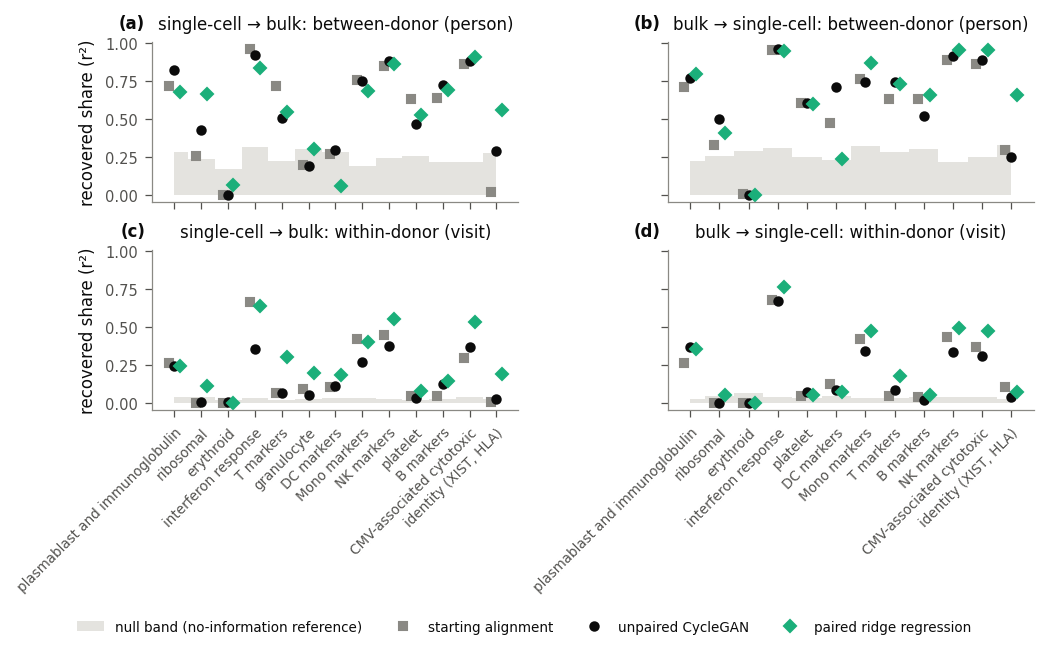

**What the translations recover is mostly the person, not the visit; the unpaired CycleGAN recovers about what its starting alignment already does (less for interferon, platelet and monocytes in single-cell → bulk; more for plasmablast and T markers in bulk → single-cell), and paired ridge regression recovers more of the visit.** For each short-list program (x axis, ordered by the share of its variance that lies between donors in the 582 training targets: visit-level programs on the left, person-level on the right), the share of the true score's between-donor (a, b) and within-donor (c, d) variation that each translator recovers on the 135 validation pairs (14 donors), as r² within that component, where r is the Pearson correlation between translated and true program scores across donor means (between-donor) or after removing each donor's mean (within-donor). (a, c) Single-cell → bulk; (b, d) bulk → single-cell. Gray squares: the starting alignment (mean shift for single-cell → bulk, ComBat for bulk → single-cell); black circles: the unpaired CycleGAN (locked models, mean of 3 seeds); green diamonds: paired ridge regression on all training pairs. Gray band: the square of the 97.5th percentile of r for 200 random real profiles (the no-information reference). No component falls below the 10% estimability threshold. Program scores are means of genes z-scored with the training targets' mean and standard deviation; the granulocyte score is the plain mean of its 7 genes and is shown for single-cell → bulk only.

In [7]:
# Figure 9.1: person versus visit. Recovered share (r² in each component) per program, ordered by the training between-donor share
SHOWN = {"start": (MUTED, "s"), "unpaired CycleGAN": (INK, "o"), "paired ridge regression": (SERIES[2], "D")}
fig, axs = figure("double", 4.2, 2, 2, sharey=True, sharex="col")
for i, d in enumerate(DIRS):                                    # columns: directions; rows: between-, within-donor
    order = share_tab[share_tab.direction == label(d)].sort_values("between-donor share (training)")["program"].tolist()
    x = np.arange(len(order))
    for j, comp_ in enumerate(("between", "within")):
        a = axs[j, i]
        nul = [NULL[(d, p)][1, 1 if comp_ == "between" else 2] ** 2 for p in order]
        a.fill_between(x, 0, nul, color="#e4e3df", step="mid", lw=0, label="null band (no-information reference)")
        for k, (tname, (col, mk)) in enumerate(SHOWN.items()):
            t = track[(track.direction == label(d)) & (track.translator == tname)].set_index("program").loc[order]
            v = t[f"recovered {comp_} share"].to_numpy()
            a.plot(x + (k - 1) * 0.2, v, ls="", marker=mk, color=col, ms=4, label=SHOWN_NAME.get(tname, tname))
        a.set_xticks(x, order, rotation=45, ha="right", rotation_mode="anchor", fontsize=6.5)
        a.tick_params(axis="x", labelbottom=(j == 1))
        a.set_title(f"{label(d)}: {comp_}-donor ({'person' if comp_ == 'between' else 'visit'})")
        if i == 0:
            a.set_ylabel("recovered share (r²)")
h, l = axs[0, 0].get_legend_handles_labels()
assert track["recovered between share"].notna().all() and track["recovered within share"].notna().all()   # no component under 10%
fig.legend(h, l, loc="outside lower center", ncol=5, fontsize=6.5)
panel_labels(axs.ravel(), y=1.06)
save_show(fig, FIG, "9.1_person_vs_visit")
show_caption("9.1_person_vs_visit")

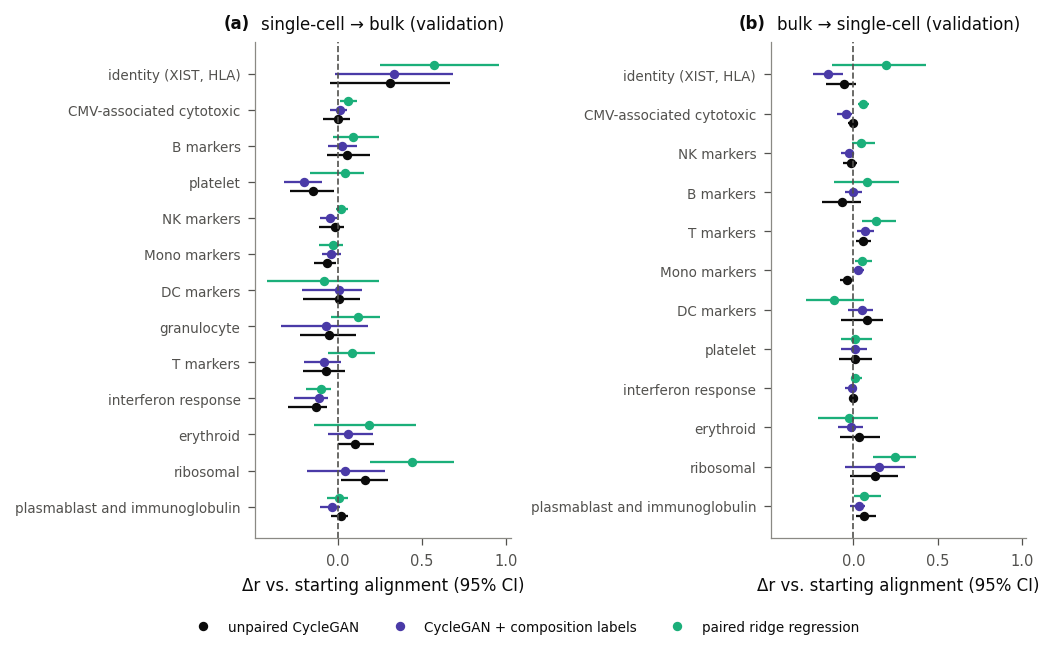

**Paired ridge regression improves on the starting alignment for several programs; the unpaired CycleGAN mostly does not, and in single-cell → bulk it falls below its start for the interferon, platelet and monocyte programs.** For each short-list program, the change in tracking correlation Δr (Pearson r across the 135 validation samples between the translated and the true program score, minus the same r for the starting alignment), with paired donor-bootstrap 95% confidence intervals (CIs; 1,000 resamples of the 14 donors), for the unpaired CycleGAN (black), CycleGAN + composition labels (purple; both locked models, mean of 3 seeds) and paired ridge regression (green). (a) Single-cell → bulk; (b) bulk → single-cell. Programs are ordered as in Figure 9.1. The dashed line marks no change from the start. The CycleGANs' intervals are optimistic, since the validation donors chose them.

In [8]:
# Figure 9.2: Δr against the start, with paired ridge, per program (donor-bootstrap 95% CIs)
SHOW2 = {"unpaired CycleGAN": INK, "CycleGAN + composition labels": SERIES[6], "paired ridge regression": SERIES[2]}
from matplotlib.ticker import FuncFormatter
fig, axs = figure("double", 4.2, 1, 2, sharex=True)
for a, d in zip(axs, DIRS):
    order = share_tab[share_tab.direction == label(d)].sort_values("between-donor share (training)")["program"].tolist()
    y = np.arange(len(order))
    for k, (tname, col) in enumerate(SHOW2.items()):
        t = track[(track.direction == label(d)) & (track.translator == tname)].set_index("program").loc[order]
        yy = y + (k - 1) * 0.25
        a.hlines(yy, t["Δr lo"], t["Δr hi"], color=col, lw=1.1)
        a.plot(t["Δr vs start"], yy, "o", color=col, ms=3.5, label=tname)
    a.axvline(0, **THRESHOLD)
    a.set_yticks(y, order, fontsize=6.5)
    a.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.1f}".replace("-0.0", "0.0").replace("-", "−")))
    a.set(xlabel="Δr vs. starting alignment (95% CI)", title=f"{label(d)} (validation)")
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc="outside lower center", ncol=3, fontsize=6.5)
panel_labels(axs)
save_show(fig, FIG, "9.2_delta_vs_start")
show_caption("9.2_delta_vs_start")

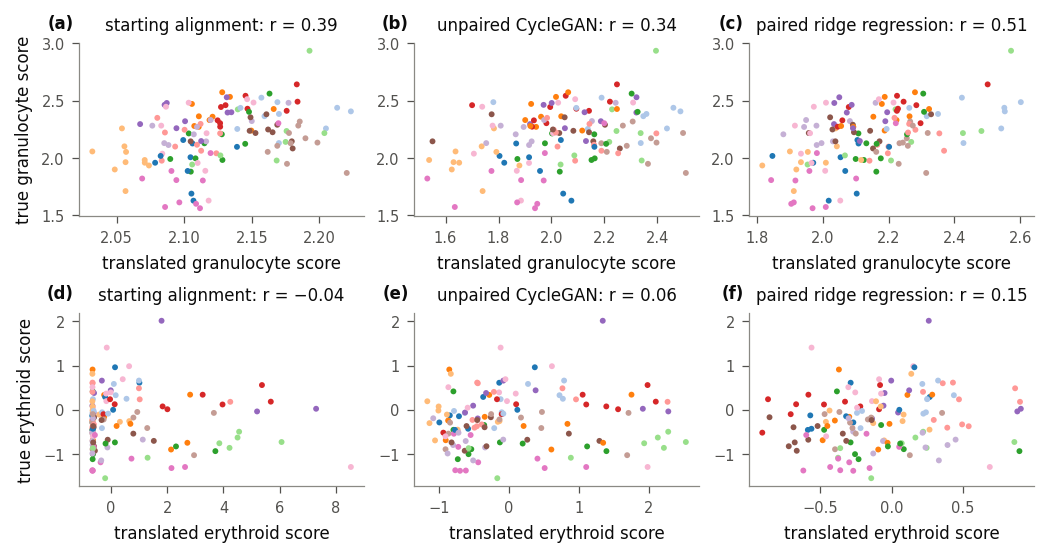

**Whole-blood signal that peripheral blood mononuclear cells (PBMCs) lack is barely inferred from the single-cell input: only paired ridge regression tracks the granulocyte program, and nothing tracks the erythroid program.** Single-cell → bulk translations of the 135 validation samples (14 donors): the translated against the true score of the granulocyte program (a–c; plain mean of FCGR3B, CSF3R, CXCR2, CXCR1, FPR1, CMTM2 and MME) and of the erythroid program (d–f; ALAS2, HBB, HBA1, HBA2, CA1, SLC4A1, HBD, AHSP), for the starting alignment (mean shift; a, d), the unpaired CycleGAN (locked, mean of 3 seeds; b, e) and paired ridge regression (c, f). Points are colored by donor. The r in each title is the Pearson correlation's point estimate, not the reading: under the fixed rule a program is "tracked" only when the lower bound of the donor-bootstrap 95% confidence interval (CI) exceeds the no-information reference's 97.5th percentile (granulocyte: start 0.388, CI 0.109 to 0.562; unpaired CycleGAN 0.337, CI 0.030 to 0.498; paired ridge regression 0.507, CI 0.258 to 0.671; null 0.150; ridge's gain over the start, Δr 0.119, CI −0.039 to 0.253, is not resolved). The start's granulocyte scores span only about 0.2 units against about 1.4 for the true scores: mean shift adds the training-average whole-blood signal but almost no sample-to-sample variation.

In [9]:
# Figure 9.3: signal the input lacks (single-cell -> bulk): translated vs true granulocyte and erythroid scores, colored by donor
d = "S->B"
dcol = {dn: plt.cm.tab20(i % 20) for i, dn in enumerate(pd.unique(donors_va))}
cs = [dcol[x] for x in donors_va]
fig, axs = figure("double", 3.6, 2, 3)
for i, p in enumerate(("granulocyte", "erythroid")):
    true = score(ctx0.tgt[d], p, d)
    for j, tname in enumerate(("start", "M1", "ridge + spread")):
        a = axs[i, j]
        pred = np.mean(member_scores(tname, d, p), 0)
        a.scatter(pred, true, s=8, c=cs, lw=0)
        r = track[(track.direction == label(d)) & (track.program == p) & (track.translator == NAMES[tname])].iloc[0]
        a.set_title(f"{SHOWN_NAME.get(NAMES[tname], NAMES[tname])}: r = {r['r']:.2f}".replace("-", "−"))
        a.set(xlabel=f"translated {p} score", ylabel=f"true {p} score" if j == 0 else "")
panel_labels(axs.ravel(), y=1.06)
save_show(fig, FIG, "9.3_absent_cells")
show_caption("9.3_absent_cells")

### 4.3 The vaccine response

**The Day 7 plasmablast response is present and the start, the unpaired CycleGAN and paired ridge regression each follow it partly; only paired ridge regression meets the tracking rule, in bulk → single-cell.** The gate passes in both assays (training change 0.494, 95% CI 0.276 to 0.722, in bulk; 0.381, 0.209 to 0.562, in single-cell profiles), and the response is present in the validation profiles (0.532, 0.295 to 0.859; 0.365, 0.126 to 0.642; Tables 9.4 and 9.5, Figure 9.4). The start, the unpaired CycleGAN and paired ridge regression follow donor-years' changes about equally (r 0.61–0.74), but their lower bounds stay below the null band's upper end, except paired ridge regression in bulk → single-cell (r 0.736, 95% CI 0.507 to 0.889; null 0.431). The averaged-weight unpaired CycleGAN also meets the rule there, by a margin of 0.01 (lower bound 0.441 against 0.431), while the locked model does not (0.407). Paired ridge regression misses the rule in single-cell → bulk by a similar margin (0.420 against 0.432). These are validation values on the donors that chose the CycleGANs, so they favor the CycleGANs. The interferon change is not present at Day 7, as expected, so its readings cannot be judged.

In [10]:
# Donor-year units with Day 0 and Day 7 of a flu-vaccine year; the training gate per target assay
U = {s: bi.donor_years(tp[s], P.donor_ids[rows(s)]) for s in ("train", "val")}
print({s: (len(u), u.donor.nunique()) for s, u in U.items()})
VAX = ["plasmablast and immunoglobulin", "interferon response"]
def change(Y, p, d, u):
    s = score(Y, p, d)
    return s[u["day7"].to_numpy()] - s[u["day0"].to_numpy()]
def ci_units(vals, units, n_boot=1000):
    bs = bi.unit_boot(units, n_boot, seed=0)
    m = np.array([np.mean(vals[b]) for b in bs])
    return float(np.mean(vals)), *np.percentile(m, [2.5, 97.5])
gate_rows = []
for d in DIRS:
    Yt = TGT_ALL[d][rows("train")]
    for p in VAX:
        e, lo, hi = ci_units(change(Yt, p, d, U["train"]), U["train"])
        gate_rows.append({"target assay": "bulk" if d == "S->B" else "single-cell", "direction": label(d), "program": p,
                          "training change": e, "CI low": lo, "CI high": hi, "gate passed": bool(lo > 0) if p.startswith("plasmablast") else np.nan})
gate = pd.DataFrame(gate_rows)
gate.to_csv(RESULTS / "vaccine_gate_train.csv", index=False)
show_table("**Table 9.4.** The vaccine-response gate: mean Day 7 − Day 0 change in program score (training SD units) over the "
           "116 training donor-years, with donor-bootstrap 95% CIs; the gate passes when the plasmablast CI lies above 0.",
           gate, {"CI low": "95% CI low", "CI high": "95% CI high"})

{'train': (116, 64), 'val': (26, 14)}


**Table 9.4.** The vaccine-response gate: mean Day 7 − Day 0 change in program score (training SD units) over the 116 training donor-years, with donor-bootstrap 95% CIs; the gate passes when the plasmablast CI lies above 0.

,target assay,direction,program,training change,95% CI low,95% CI high,gate passed
0,bulk,single-cell → bulk,plasmablast and immunoglobulin,0.494,0.276,0.722,True
1,bulk,single-cell → bulk,interferon response,-0.136,-0.229,-0.055,NaN
2,single-cell,bulk → single-cell,plasmablast and immunoglobulin,0.381,0.209,0.562,True
3,single-cell,bulk → single-cell,interferon response,-0.160,-0.288,-0.050,NaN


In [11]:
# On validation: the true change, and each translator's change, r with the true change and Δ against the start
vax_rows, VAXPTS = [], {}
for d in DIRS:
    u = U["val"]
    passed = bool(gate[(gate.direction == label(d)) & gate.program.str.startswith("plasmablast")]["gate passed"].iloc[0])
    for p in VAX:
        true = change(ctx0.tgt[d], p, d, u)
        te, tlo, thi = ci_units(true, u)
        present = not (tlo <= 0 <= thi)
        bs = bi.unit_boot(u, 1000, seed=0)
        start_ch = [change(y, p, d, u) for y in OUT[("start", d)]]
        for name in NAMES:
            chs = [change(y, p, d, u) for y in OUT[(name, d)]]
            VAXPTS[(d, p, name)] = (true, np.mean(chs, 0))
            mean_ch = np.mean([c.mean() for c in chs])
            mb = np.array([np.mean([c[b].mean() for c in chs]) for b in bs])
            rb = np.array([np.nanmean([bi.pearson(true[b], c[b]) for c in chs]) - np.nanmean([bi.pearson(true[b], c[b]) for c in start_ch]) for b in bs])
            r = np.nanmean([bi.pearson(true, c) for c in chs])
            rbs = np.array([np.nanmean([bi.pearson(true[b], c[b]) for c in chs]) for b in bs])
            null = np.array([bi.pearson(true, change(noinfo(d, s), p, d, u)) for s in NULL_SEEDS])
            vax_rows.append({"direction": label(d), "program": p, "gate passed": passed, "translator": NAMES[name],
                             "true change": te, "true CI": f"{tlo:.3f} to {thi:.3f}", "true present": present,
                             "translated change": mean_ch, "translated CI": "{:.3f} to {:.3f}".format(*np.percentile(mb, [2.5, 97.5])),
                             "r with true change": r, "r CI": "{:.3f} to {:.3f}".format(*np.nanpercentile(rbs, [2.5, 97.5])),
                             "r lo": np.nanpercentile(rbs, 2.5), "null r 97.5%": np.percentile(null, 97.5),
                             "Δr vs start": r - np.nanmean([bi.pearson(true, c) for c in start_ch]),
                             "Δr vs start CI": "{:.3f} to {:.3f}".format(*np.nanpercentile(rb, [2.5, 97.5]))})
vax = pd.DataFrame(vax_rows)
def vax_reading(r):
    if not r["gate passed"]:
        return "no detectable response at this resolution"
    if not r["true present"]:
        return "cannot be judged"
    return "tracked" if r["r lo"] > r["null r 97.5%"] else "not tracked"
vax["reading"] = vax.apply(vax_reading, axis=1)
vax.to_csv(RESULTS / "vaccine_response_val.csv", index=False)
show_table("**Table 9.5.** The vaccine response on the 26 validation donor-years (14 donors): the true and translated mean "
           "Day 7 − Day 0 change with donor-bootstrap 95% CIs, the r between translated and true changes across donor-years with "
           "its CI and lower bound, the 97.5th percentile of r under the no-information reference (200 draws), Δr against the "
           "starting alignment, and the reading under the fixed rules (§3).",
           vax, {"true CI": "true 95% CI", "true present": "true change present", "translated CI": "translated 95% CI",
                 "r CI": "r 95% CI", "r lo": "r CI low", "null r 97.5%": "null r 97.5th percentile",
                 "Δr vs start": "Δr vs. start", "Δr vs start CI": "Δr 95% CI"})

**Table 9.5.** The vaccine response on the 26 validation donor-years (14 donors): the true and translated mean Day 7 − Day 0 change with donor-bootstrap 95% CIs, the r between translated and true changes across donor-years with its CI and lower bound, the 97.5th percentile of r under the no-information reference (200 draws), Δr against the starting alignment, and the reading under the fixed rules (§3).

,direction,program,gate passed,translator,true change,true 95% CI,true change present,translated change,translated 95% CI,r with true change,r 95% CI,r CI low,null r 97.5th percentile,Δr vs. start,Δr 95% CI,reading
0,single-cell → bulk,plasmablast and immunoglobulin,True,starting alignment,0.532,0.295 to 0.859,True,0.268,0.075 to 0.484,0.634,0.399 to 0.837,0.399,0.432,0.000,0.000 to 0.000,not tracked
1,single-cell → bulk,plasmablast and immunoglobulin,True,unpaired CycleGAN,0.532,0.295 to 0.859,True,0.482,0.223 to 0.782,0.619,0.384 to 0.809,0.384,0.432,-0.016,-0.058 to 0.019,not tracked
2,single-cell → bulk,plasmablast and immunoglobulin,True,CycleGAN + composition labels,0.532,0.295 to 0.859,True,0.432,0.198 to 0.682,0.511,0.227 to 0.761,0.227,0.432,-0.123,-0.256 to -0.027,not tracked
3,single-cell → bulk,plasmablast and immunoglobulin,True,unpaired CycleGAN (averaged),0.532,0.295 to 0.859,True,0.473,0.233 to 0.751,0.608,0.399 to 0.774,0.399,0.432,-0.027,-0.084 to 0.019,not tracked
4,single-cell → bulk,plasmablast and immunoglobulin,True,CycleGAN + composition labels (averaged),0.532,0.295 to 0.859,True,0.436,0.220 to 0.657,0.403,0.074 to 0.734,0.074,0.432,-0.231,-0.462 to -0.023,not tracked
5,single-cell → bulk,plasmablast and immunoglobulin,True,CycleGAN + cross-fitted labels (averaged),0.532,0.295 to 0.859,True,0.375,0.134 to 0.624,0.488,0.194 to 0.750,0.194,0.432,-0.146,-0.297 to -0.034,not tracked
6,single-cell → bulk,plasmablast and immunoglobulin,True,paired ridge regression,0.532,0.295 to 0.859,True,0.300,0.005 to 0.607,0.610,0.420 to 0.813,0.420,0.432,-0.024,-0.088 to 0.074,not tracked
7,single-cell → bulk,interferon response,True,starting alignment,0.119,-0.184 to 0.448,False,0.069,-0.076 to 0.217,0.884,0.804 to 0.983,0.804,0.411,0.000,0.000 to 0.000,cannot be judged
8,single-cell → bulk,interferon response,True,unpaired CycleGAN,0.119,-0.184 to 0.448,False,0.185,-0.065 to 0.462,0.868,0.771 to 0.977,0.771,0.411,-0.017,-0.050 to 0.003,cannot be judged
9,single-cell → bulk,interferon response,True,CycleGAN + composition labels,0.119,-0.184 to 0.448,False,0.149,-0.103 to 0.426,0.833,0.728 to 0.961,0.728,0.411,-0.051,-0.090 to -0.012,cannot be judged


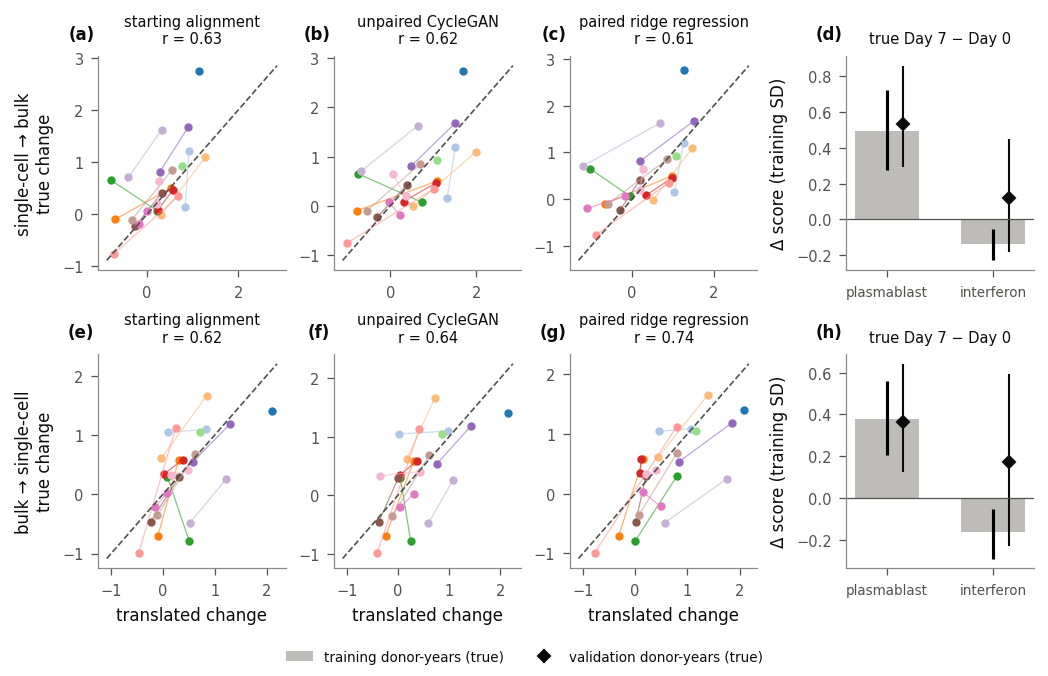

**The Day 7 plasmablast response to flu vaccination is present in the true profiles, but among the translators shown only paired ridge regression meets the fixed tracking rule, in bulk → single-cell.** The averaged-weight unpaired CycleGAN (not shown) also meets it there, by 0.01 (lower bound 0.441 against 0.431), on the donors that chose it. The starting alignment, the unpaired CycleGAN and paired ridge regression follow the response about equally, and in single-cell → bulk the CycleGANs with composition labels follow it less than the start (Table 9.5). (a–c, e–g) For each validation donor-year with Day 0 and Day 7 draws of a flu-vaccine year (26 donor-years, 14 donors; a donor's two years joined by a line, colors by donor), the Day 7 − Day 0 change in the plasmablast and immunoglobulin program score, translated (x) against true (y), for the starting alignment, the unpaired CycleGAN (locked, mean of 3 seeds) and paired ridge regression; the dashed line is equality. (a–c) Single-cell → bulk; (e–g) bulk → single-cell. The r in each title is the Pearson correlation's point estimate, not the reading: in single-cell → bulk, for example, the start's r of 0.63 reads "not tracked" because the lower bound of its donor-bootstrap 95% confidence interval (CI; 0.399) lies below the null's 97.5th percentile (0.432). (d, h) The true change in the target assay, in training standard-deviation (SD) units: bars, the 116 training donor-years with donor-bootstrap 95% CIs (the gate: plasmablast must rise); diamonds, the validation donor-years with their CIs. The interferon response peaks around Day 1 after inactivated vaccine and has fallen by Day 7 in training, so it is a secondary readout with an expected null; on validation its mean change is not present, so the translators' interferon readings are "cannot be judged", although their changes follow the donor-years' interferon changes closely (r 0.70–0.95 against a null of about 0.4).

In [12]:
# Figure 9.4: the vaccine response. Day 7 - Day 0 plasmablast change, true vs translated per donor-year (validation),
# the two years of a donor joined; the training response alongside; interferon in the last column
fig, axs = figure("double", 4.4, 2, 4)
for i, d in enumerate(DIRS):
    u = U["val"]
    for j, tname in enumerate(("start", "M1", "ridge + spread")):
        a = axs[i, j]
        true, pred = VAXPTS[(d, "plasmablast and immunoglobulin", tname)]
        for dn in pd.unique(u.donor):
            m = (u.donor == dn).to_numpy()
            if m.sum() == 2:
                a.plot(pred[m], true[m], color=dcol[dn], lw=0.6, alpha=0.6)
            a.plot(pred[m], true[m], "o", color=dcol[dn], ms=3)
        lim = [min(true.min(), pred.min()) - 0.1, max(true.max(), pred.max()) + 0.1]
        a.plot(lim, lim, **THRESHOLD)
        row = vax[(vax.direction == label(d)) & (vax.program.str.startswith("plasmablast")) & (vax.translator == NAMES[tname])].iloc[0]
        a.set_title(f"{SHOWN_NAME.get(NAMES[tname], NAMES[tname])}\nr = {row['r with true change']:.2f}", fontsize=7)
        a.set(xlabel="translated change" if i == 1 else "", ylabel=f"{label(d)}\ntrue change" if j == 0 else "")
    a = axs[i, 3]
    g = gate[gate.direction == label(d)]
    vrow = [vax[(vax.direction == label(d)) & (vax.program == p) & (vax.translator == "start")].iloc[0] for p in VAX]
    yv = [r_["true change"] for r_ in vrow]
    lohi = [[float(v) for v in r_["true CI"].split(" to ")] for r_ in vrow]
    a.bar([0, 1], g["training change"], yerr=[g["training change"] - g["CI low"], g["CI high"] - g["training change"]],
          color="#bdbcb8", width=0.6, label="training donor-years (true)")
    a.errorbar([0.15, 1.15], yv, yerr=[[y_ - lh[0] for y_, lh in zip(yv, lohi)], [lh[1] - y_ for y_, lh in zip(yv, lohi)]],
               fmt="D", color=INK, ms=4, lw=1, label="validation donor-years (true)")
    a.set_ylabel("Δ score (training SD)")
    a.axhline(0, color=INK_2, lw=0.6)
    a.set_xticks([0, 1], ["plasmablast", "interferon"], fontsize=6.5)
    a.set_title("true Day 7 − Day 0", fontsize=7)
h, l = axs[0, 3].get_legend_handles_labels()
fig.legend(h, l, loc="outside lower center", ncol=2, fontsize=6.5)
panel_labels(axs.ravel(), y=1.06)
save_show(fig, FIG, "9.4_vaccine_response")
show_caption("9.4_vaccine_response")

### 4.4 Traits of the person

**Every translator keeps the direction of the sex difference, but only paired ridge regression gets its size right, in single-cell → bulk.** The true female − male XIST difference is 1.49 training SD in bulk and 1.98 in single-cell profiles (Table 9.6). In single-cell → bulk the start exaggerates it about six-fold (ratio of translated to true difference 6.05), because mean shift carries the single-cell gap into bulk units; the unpaired CycleGAN pulls the ratio to 1.96, and paired ridge regression matches the true difference (1.02). In bulk → single-cell every translator understates it (start 0.11, unpaired CycleGAN 0.27), and paired ridge regression comes closest (0.76). In bulk → single-cell the CycleGANs also separate the sexes less cleanly: the donor-level AUROC of translated XIST is 1.00 for the start and paired ridge regression but 0.73 to 0.85 for the CycleGANs. The CMV-program difference has wide intervals for every translator (14 donors). As throughout, these are validation values on the donors that chose the CycleGANs.

In [13]:
# Sex (XIST), CMV (the CMV-associated program) and HLA genes; bootstrap stratified by the trait
from sklearn.metrics import roc_auc_score
meta_va = META.loc[va]
sex = {dn: s for dn, s in zip(meta_va.donor_id, meta_va.sex)}
cmv = {dn: s for dn, s in zip(meta_va.donor_id, meta_va.cmv)}
print("validation donors:", pd.Series(sex).value_counts().to_dict(), pd.Series(cmv).value_counts().to_dict())
xi = gi["XIST"]
trait_rows = []
for d in DIRS:
    sd_x = mu_t[d][1][xi]
    fem = np.array([sex[x] == "Female" for x in donors_va]); pos = np.array([cmv[x] == "Positive" for x in donors_va])
    bs_sex, bs_cmv = bi.strat_boot(donors_va, sex, 1000, 0), bi.strat_boot(donors_va, cmv, 1000, 0)
    def diff(v, m, idx):
        return (v[idx][m[idx]].mean() - v[idx][~m[idx]].mean())
    true_x = ctx0.tgt[d][:, xi]; true_c = score(ctx0.tgt[d], "CMV-associated cytotoxic", d)
    true_xdiff = diff(true_x, fem, np.arange(n_va)) / sd_x
    for name in ["true"] + list(NAMES):
        xs = [true_x] if name == "true" else [y[:, xi] for y in OUT[(name, d)]]
        cs = [true_c] if name == "true" else member_scores(name, d, "CMV-associated cytotoxic")
        e_s = np.mean([diff(x, fem, np.arange(n_va)) for x in xs]) / sd_x
        b_s = np.array([np.mean([diff(x, fem, b) for x in xs]) / sd_x for b in bs_sex])
        e_c = np.mean([diff(c, pos, np.arange(n_va)) for c in cs])
        b_c = np.array([np.mean([diff(c, pos, b) for c in cs]) for b in bs_cmv])
        dm = [bi.donor_means(x, donors_va) for x in xs]
        auc = np.mean([roc_auc_score([sex[l] == "Female" for l in labs], m) for m, labs in dm])
        hla = {g: np.nanmean([bi.tracking(ctx0.tgt[d][:, gi[g]], y[:, gi[g]], donors_va)["between r"] for y in OUT[(name, d)]]) if name != "true" else 1.0
               for g in ("HLA-DRB5", "HLA-DQA1", "HLA-DQB1", "HLA-DQA2")}
        trait_rows.append({"direction": label(d), "translator": NAMES.get(name, "true target"),
                           "XIST female − male (training SD)": e_s, "XIST CI": "{:.2f} to {:.2f}".format(*np.percentile(b_s, [2.5, 97.5])),
                           "XIST translated / true difference": e_s / true_xdiff, "XIST donor AUROC": auc, "CMV program, positive − negative": e_c,
                           "CMV CI": "{:.2f} to {:.2f}".format(*np.percentile(b_c, [2.5, 97.5])),
                           **{f"{g} between r": v for g, v in hla.items()}})
traits = pd.DataFrame(trait_rows)
traits.to_csv(RESULTS / "person_traits_val.csv", index=False)
show_table("**Table 9.6.** Traits of the person on the 135 validation pairs (14 donors): the female − male XIST difference "
           "(training SD units; 9 female, 5 male donors) with its 95% CI and its ratio to the true difference, the donor-level AUROC "
           "of XIST for sex, the CMV-positive − CMV-negative difference in the CMV-associated program (8 positive, 6 negative) "
           "with its 95% CI, and the between-donor r of four HLA genes. Bootstraps (1,000) are stratified by the trait.",
           traits, {"XIST CI": "XIST 95% CI", "CMV CI": "CMV 95% CI"})

validation donors: {'Female': 9, 'Male': 5} {'Positive': 8, 'Negative': 6}


**Table 9.6.** Traits of the person on the 135 validation pairs (14 donors): the female − male XIST difference (training SD units; 9 female, 5 male donors) with its 95% CI and its ratio to the true difference, the donor-level AUROC of XIST for sex, the CMV-positive − CMV-negative difference in the CMV-associated program (8 positive, 6 negative) with its 95% CI, and the between-donor r of four HLA genes. Bootstraps (1,000) are stratified by the trait.

,direction,translator,XIST female − male (training SD),XIST 95% CI,XIST translated / true difference,XIST donor AUROC,"CMV program, positive − negative",CMV 95% CI,HLA-DRB5 between r,HLA-DQA1 between r,HLA-DQB1 between r,HLA-DQA2 between r
0,single-cell → bulk,true target,1.490,1.23 to 1.76,1.000,1.000,0.594,0.01 to 1.12,1.000,1.000,1.000,1.000
1,single-cell → bulk,starting alignment,9.014,8.41 to 9.62,6.049,1.000,0.809,0.23 to 1.37,0.842,0.862,0.668,0.924
2,single-cell → bulk,unpaired CycleGAN,2.922,1.93 to 4.07,1.961,1.000,0.409,-0.18 to 0.96,0.866,0.896,0.837,0.885
3,single-cell → bulk,CycleGAN + composition labels,2.358,1.72 to 3.04,1.582,0.978,0.535,-0.01 to 1.05,0.900,0.843,0.831,0.823
4,single-cell → bulk,unpaired CycleGAN (averaged),2.772,2.01 to 3.50,1.860,1.000,0.532,-0.04 to 1.09,0.853,0.871,0.824,0.870
5,single-cell → bulk,CycleGAN + composition labels (averaged),3.416,2.39 to 4.40,2.293,1.000,0.466,-0.09 to 1.01,0.836,0.731,0.638,0.772
6,single-cell → bulk,CycleGAN + cross-fitted labels (averaged),3.213,2.24 to 4.28,2.156,1.000,0.303,-0.18 to 0.78,0.858,0.792,0.749,0.821
7,single-cell → bulk,paired ridge regression,1.515,1.31 to 1.75,1.016,1.000,0.704,0.09 to 1.31,0.733,0.838,0.848,0.838
8,bulk → single-cell,true target,1.985,1.91 to 2.05,1.000,1.000,0.783,0.23 to 1.34,1.000,1.000,1.000,1.000
9,bulk → single-cell,starting alignment,0.217,0.18 to 0.26,0.109,1.000,0.473,-0.00 to 0.91,0.841,0.862,0.668,0.931


### 4.5 What adversarial training changes

**Beyond its starting alignment, the unpaired CycleGAN's changes carry little information about the specific sample, no more than an unpaired alignment's.** Across all genes (Table 9.7), the median partial correlation of its move with the true partner, given the start, is 0.047 (95% CI 0.014 to 0.089) in single-cell → bulk and 0.077 (0.049 to 0.112) in bulk → single-cell, against a null band of about ±0.03 to ±0.07. That is no different from the unpaired CORAL alignment in single-cell → bulk (difference 0.006, −0.032 to 0.048) and below it in bulk → single-cell (−0.113, −0.167 to −0.053). Paired ridge regression's moves carry more: 0.162 (0.103 to 0.204) and 0.248 (0.193 to 0.305) above the CycleGAN. The partial correlation ignores scale, so CORAL's higher value does not make it a better translator: its validation accuracy is lower (centered R² −0.58 in single-cell → bulk and −0.98 in bulk → single-cell, against −0.26 and −0.19 for the unpaired CycleGAN; Phase 3). Per-program values are in Table 9.8 only. The validation donors chose the CycleGANs, so the CycleGAN values here are, if anything, optimistic.

In [14]:
# Per gene: mean |move|; the partial r of the move with the true partner controlling for the start (the headline measure);
# the move excess and the shrinkage reference's excess are context only (their difference is not a valid null correction)
oth = bi.other_donor(donors_va, seed=0)
move_rows = []
for d in DIRS:
    s0, T = OUT[("start", d)][0], ctx0.tgt[d]
    mean_half = np.asarray(HT[d], float).mean(0)
    shrink = s0 + bi.SHRINK * (mean_half - s0)
    ex_ref = bi.move_excess(shrink, s0, T, T[oth])
    assert np.all(np.isnan(bi.partial_move_r(shrink, s0, T)) | (np.abs(bi.partial_move_r(shrink, s0, T)) < 1e-6))
    sd = mu_t[d][1]
    coral = an.frontier_members(P, ctx0.half_a, ctx0.half_b, ctx0.src[d], d)["CORAL"]    # unpaired, uses all genes
    null_pr = np.stack([bi.partial_move_r(noinfo(d, sd_), s0, T) for sd_ in NULL_SEEDS])  # no-information move, 200 seeds
    REF_D = {"CORAL (unpaired reference)": [np.asarray(coral, float)]}
    for name in ("M1", "M2", "ridge + spread", "CORAL (unpaired reference)"):
        ys = REF_D[name] if name in REF_D else OUT[(name, d)]
        pr = np.nanmean([bi.partial_move_r(y, s0, T) for y in ys], 0)
        ex = np.nanmean([bi.move_excess(y, s0, T, T[oth]) for y in ys], 0)
        mv = np.mean([np.abs(y - s0).mean(0) / sd for y in ys], 0)
        for p in PROGS[d] + ["all genes"]:
            c = cols(SHORT[p]) if p != "all genes" else np.arange(NG)
            nb_ = np.nanmedian(null_pr[:, c], 1)                 # the program median under each no-information draw
            move_rows.append({"direction": label(d), "translator": NAMES.get(name, name), "program": p,
                              "mean |move| (training SD)": float(np.mean(mv[c])),
                              "partial r of move with partner, given start (median)": float(np.nanmedian(pr[c])),
                              "null 2.5%": float(np.nanpercentile(nb_, 2.5)), "null 97.5%": float(np.nanpercentile(nb_, 97.5)),
                              "move excess (median, context)": float(np.nanmedian(ex[c])),
                              "shrinkage reference excess (median, context)": float(np.nanmedian(ex_ref[c]))})
moves = pd.DataFrame(move_rows)

# All genes: donor-bootstrap 95% CIs for each translator's median partial r and for the differences that the text compares
ALLG = {"unpaired CycleGAN": "M1", "CycleGAN + composition labels": "M2", "paired ridge regression": "ridge + spread"}
all_rows = []
for d in DIRS:
    s0, T = OUT[("start", d)][0], ctx0.tgt[d]
    coral = np.asarray(an.frontier_members(P, ctx0.half_a, ctx0.half_b, ctx0.src[d], d)["CORAL"], float)
    sets_ = {k: OUT[(v, d)] for k, v in ALLG.items()}
    sets_["CORAL (unpaired reference)"] = [coral]
    def med(ys, idx):
        return float(np.nanmedian(np.nanmean([bi.partial_move_r(y[idx], s0[idx], T[idx]) for y in ys], 0)))
    boots = {k: np.array([med(ys, b) for b, _ in BOOTL]) for k, ys in sets_.items()}
    est = {k: med(ys, np.arange(n_va)) for k, ys in sets_.items()}
    for k in sets_:
        all_rows.append({"direction": label(d), "comparison": k, "median partial r": est[k],
                         "95% CI": "{:.3f} to {:.3f}".format(*np.nanpercentile(boots[k], [2.5, 97.5]))})
    for a_, b_ in (("unpaired CycleGAN", "CORAL (unpaired reference)"), ("paired ridge regression", "unpaired CycleGAN")):
        diff = boots[a_] - boots[b_]
        all_rows.append({"direction": label(d), "comparison": f"{a_} − {b_}", "median partial r": est[a_] - est[b_],
                         "95% CI": "{:.3f} to {:.3f}".format(*np.nanpercentile(diff, [2.5, 97.5]))})
moves_all = pd.DataFrame(all_rows)
moves_all.to_csv(RESULTS / "moves_all_genes_val.csv", index=False)
show_table("**Table 9.7.** Over all 5,000 genes, the median partial correlation of each translator's move from its start with "
           "the true partner, given the start, on the 135 validation pairs (14 donors), and the differences compared in the text, "
           "with donor-bootstrap 95% CIs (1,000 resamples).", moves_all)
moves.to_csv(RESULTS / "moves_val.csv", index=False)
show_table("**Table 9.8.** Per program and over all genes: the mean absolute move from the start (training SD units), the "
           "median partial r of the move with the true partner given the start, and its null band (2.5th–97.5th percentile of the "
           "program median over 200 no-information draws). For context only: the move excess, per gene the r of the move with the "
           "needed correction (true partner minus start) minus its r with another donor's correction, and the same excess for a "
           "shrinkage reference (the start moved 30% of the way toward the training-half target mean, which carries no sample "
           "information); their difference is not a valid null correction.",
           moves, {"partial r of move with partner, given start (median)": "median partial r (move, partner | start)",
                   "move excess (median, context)": "move excess (median)",
                   "shrinkage reference excess (median, context)": "shrinkage-reference excess (median)"})
assert len(json.loads(TOUCH.read_text())) == 2, "test was not touched"

**Table 9.7.** Over all 5,000 genes, the median partial correlation of each translator's move from its start with the true partner, given the start, on the 135 validation pairs (14 donors), and the differences compared in the text, with donor-bootstrap 95% CIs (1,000 resamples).

,direction,comparison,median partial r,95% CI
0,single-cell → bulk,unpaired CycleGAN,0.047,0.014 to 0.089
1,single-cell → bulk,CycleGAN + composition labels,0.040,0.004 to 0.081
2,single-cell → bulk,paired ridge regression,0.210,0.137 to 0.268
3,single-cell → bulk,CORAL (unpaired reference),0.041,-0.003 to 0.097
4,single-cell → bulk,unpaired CycleGAN − CORAL (unpaired reference),0.006,-0.032 to 0.048
5,single-cell → bulk,paired ridge regression − unpaired CycleGAN,0.162,0.103 to 0.204
6,bulk → single-cell,unpaired CycleGAN,0.077,0.049 to 0.112
7,bulk → single-cell,CycleGAN + composition labels,0.085,0.058 to 0.115
8,bulk → single-cell,paired ridge regression,0.325,0.278 to 0.379
9,bulk → single-cell,CORAL (unpaired reference),0.190,0.124 to 0.247


**Table 9.8.** Per program and over all genes: the mean absolute move from the start (training SD units), the median partial r of the move with the true partner given the start, and its null band (2.5th–97.5th percentile of the program median over 200 no-information draws). For context only: the move excess, per gene the r of the move with the needed correction (true partner minus start) minus its r with another donor's correction, and the same excess for a shrinkage reference (the start moved 30% of the way toward the training-half target mean, which carries no sample information); their difference is not a valid null correction.

,direction,translator,program,mean |move| (training SD),"median partial r (move, partner | start)",null 2.5%,null 97.5%,move excess (median),shrinkage-reference excess (median)
0,single-cell → bulk,unpaired CycleGAN,granulocyte,0.595,0.125,-0.142,0.119,0.297,-0.389
1,single-cell → bulk,unpaired CycleGAN,erythroid,1.142,0.119,-0.116,0.107,0.010,0.048
2,single-cell → bulk,unpaired CycleGAN,platelet,0.613,0.044,-0.159,0.141,0.194,-0.530
3,single-cell → bulk,unpaired CycleGAN,interferon response,0.370,-0.046,-0.082,0.082,0.343,-1.085
4,single-cell → bulk,unpaired CycleGAN,plasmablast and immunoglobulin,0.398,0.160,-0.115,0.127,0.324,-0.319
5,single-cell → bulk,unpaired CycleGAN,CMV-associated cytotoxic,0.515,0.194,-0.091,0.082,0.081,-0.479
6,single-cell → bulk,unpaired CycleGAN,"identity (XIST, HLA)",1.147,0.200,-0.137,0.110,0.113,-0.264
7,single-cell → bulk,unpaired CycleGAN,T markers,0.458,0.158,-0.121,0.123,0.207,-0.425
8,single-cell → bulk,unpaired CycleGAN,B markers,0.469,0.207,-0.134,0.125,0.171,-0.218
9,single-cell → bulk,unpaired CycleGAN,Mono markers,0.549,0.083,-0.093,0.108,-0.050,-0.144


## 5. Conclusions

All results are post-hoc, on the 135 validation pairs from 14 donors; the CycleGANs' comparisons are optimistic, since these donors chose them.

- **What translations track is mostly the person, and the starting alignment already tracks it.** The starting alignment tracks 9 of 13 short-list programs in single-cell → bulk and 10 of 12 in bulk → single-cell, mostly through their between-donor component.
- **The unpaired CycleGAN mostly inherits that tracking.** It is below its start for the interferon, platelet and monocyte programs in single-cell → bulk (and above it, though neither is tracked, for the erythroid and ribosomal programs) and above it for the plasmablast and T-marker programs in bulk → single-cell. Its changes beyond the start carry no more sample-specific information than the unpaired CORAL alignment's (median partial correlation 0.047, 95% CI 0.014 to 0.089, and 0.077, 0.049 to 0.112; difference from CORAL 0.006, −0.032 to 0.048, and −0.113, −0.167 to −0.053).
- **Signal the input lacks is barely inferred.** Only paired ridge regression tracks the whole-blood granulocyte program (r 0.507, 95% CI 0.258 to 0.671; null 0.150), and its gain over the starting alignment is not resolved (Δr 0.119, 95% CI −0.039 to 0.253); nothing tracks the erythroid program.
- **A known visit-level response is present but hard to translate.** The Day 7 plasmablast rise after flu vaccination is clear in the true profiles; among the start, the locked CycleGANs and paired ridge regression, only paired ridge regression meets the tracking rule, in bulk → single-cell (r 0.736, 95% CI 0.507 to 0.889; null 0.431); the averaged-weight unpaired CycleGAN also meets it there, by 0.01 (lower bound 0.441 against 0.431), on the donors that chose it.
- **Paired supervision gets the scale of the sex difference closest** (XIST): it matches the true difference in single-cell → bulk (ratio 1.02) and comes nearest in bulk → single-cell (0.76), where the alignments and the CycleGANs exaggerate or understate it.

### Implications

- Biological claims for an unpaired translator are read against its starting alignment, since the alignment alone accounts for most of the program tracking measured here.
- On validation, only paired ridge regression met the tracking rule for the whole-blood granulocyte signal that the single-cell input lacks, and its gain over the starting alignment is not resolved (Δr 0.119, 95% CI −0.039 to 0.253).

## 6. Limitations

- **Post-hoc, on the donors that chose the models,** so every CycleGAN comparison is optimistic; 14 donors give wide intervals, especially for between-donor correlations (null band up to about ±0.5) and for the sex and CMV contrasts.
- **Program scores are linear summaries** of marker genes, so a program can track composition rather than expression within cells. In bulk → single-cell the composition-adjusted correlation addresses this; in single-cell → bulk the neutrophil fraction is unmeasured, and the granulocyte, erythroid and inflammatory programs are composition-dependent.
- **Correlation ignores scale;** slopes and the XIST ratio are reported alongside, and the move analysis is per gene and scale-free.
- **The vaccine contrast uses 26 donor-years from 14 donors** and only the Day 0 and Day 7 visits of two vaccine years.
- **Hallmark sets overlap,** and their correlations are reported as a supplementary table without intervals; no enrichment test is made.

## 7. Reproducibility

- **Runtime:** minutes on CPU; no model is trained.
- **Determinism:** the torch and BLAS thread pools are pinned and torch runs deterministic algorithms; every bootstrap and no-information draw is seeded, so a rerun reproduces every table.
- **Caches:** none is written. The notebook reads the saved models and run caches listed below and recomputes everything else on each run.
- **Inputs:** the saved Phase 3 models (checked against their registry hashes), the Phase 5 run caches (checked against their logged evaluations and Phase 5's run table), the Phase 1, 3 and 6 result tables used as checks, `data/processed/bulk_counts.h5ad` (sample metadata) and the Hallmark file `data/raw/msigdb/h.all.v2024.1.Hs.symbols.gmt` (SHA-256 checked).
- **Code:** `dgm/biology.py`; known-answer tests: `python -m tests.test_phase9`.
- **Outputs in `results/phase9/`:** program tables (`program_between_share.csv`, `program_tracking_val.csv`), the vaccine gate and response (`vaccine_gate_train.csv`, `vaccine_response_val.csv`), traits (`person_traits_val.csv`), moves (`moves_val.csv`, `moves_all_genes_val.csv`), Hallmark (`hallmark_coverage.csv`, `hallmark_tracking_val.csv`), per-gene correlations (`gene_tracking_val.npz`, `gene_tracking_by_class_val.csv`) and `figures/` with `captions.md`.

## References

- Johnson, W. E., Li, C. & Rabinovic, A. Adjusting batch effects in microarray expression data using empirical Bayes methods. *Biostatistics* 8, 118–127 (2007).
- Liberzon, A., Birger, C., Thorvaldsdóttir, H., Ghandi, M., Mesirov, J. P. & Tamayo, P. The Molecular Signatures Database (MSigDB) hallmark gene set collection. *Cell Systems* 1, 417–425 (2015).
- Sun, B., Feng, J. & Saenko, K. Return of frustratingly easy domain adaptation. *AAAI* (2016).
- Zhu, J.-Y., Park, T., Isola, P. & Efros, A. A. Unpaired image-to-image translation using cycle-consistent adversarial networks. *ICCV* (2017).